# MNIST — 3-Layer CNN built entirely with `einops` / `einsum`

All core operations — convolution (einsum over kernel positions), batch
normalization, max-pooling, flattening and fully-connected layers — are
implemented by hand
using `einops.rearrange`, `einops.reduce` and `einops.einsum` (plus a tiny
zero-padding layout helper).
No `nn.Conv2d`, `nn.BatchNorm2d`, `nn.MaxPool2d`, `nn.Linear` or `.view()` are used.

**Pipeline:** `MNIST test set (10k) → random split → 7,000 train / 3,000 test-split`
**Model:** Conv(1→32,3×3) → BN → ReLU → Pool₂ → Conv(32→64,3×3) → BN → ReLU → Pool₂ → Conv(64→128,3×3) → BN → ReLU → FC(6272→256) → ReLU → Dropout → FC(256→10)
**Training:** Adam, lr = 1e-3, batch = 128, **5 epochs**.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split

import einops
from einops import rearrange, reduce, einsum

from torchvision import datasets, transforms

torch.manual_seed(0)
np.random.seed(0)
DEVICE = "cpu"
print("torch:", torch.__version__, "| einops:", einops.__version__)

torch: 2.13.0 | einops: 0.8.2


In [2]:
# ---------------------------------------------------------------- data
# We use the MNIST test set (10,000 images) as the data pool and carve out
# a held-out test split so we can honestly report "test split accuracy".
tfm = transforms.Compose([
    transforms.ToTensor(),                      # [0,1], shape (1,28,28)
    transforms.Normalize((0.1307,), (0.3081,)), # MNIST mean/std
])
pool = datasets.MNIST(".", train=False, download=True, transform=tfm)

g = torch.Generator().manual_seed(0)
train_ds, test_ds = random_split(pool, [7000, 3000], generator=g)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)
print(f"train: {len(train_ds)} | test split: {len(test_ds)}")

train: 7000 | test split: 3000


In [3]:
# ------------------------------------------------- einops building blocks

def pad2d(x, p, value=0.0):
    """Symmetric spatial padding (layout op, mirrors einops.pad)."""
    out = torch.full(x.shape[:2] + (x.shape[2] + 2 * p, x.shape[3] + 2 * p),
                     value, dtype=x.dtype, device=x.device)
    out[:, :, p:p + x.shape[2], p:p + x.shape[3]] = x
    return out


class Conv2dEinops(nn.Module):
    """Conv2d as a sum of `einops.einsum` calls over kernel positions:
    for each (i, j) the shifted input is contracted with the matching
    kernel slice, and the 9 partial maps are accumulated."""
    def __init__(self, cin, cout, k, stride=1, p=0, bias=True):
        super().__init__()
        self.k, self.stride, self.p = k, stride, p
        self.weight = nn.Parameter(torch.empty(cout, cin, k, k))
        nn.init.kaiming_uniform_(self.weight, a=5 ** 0.5)
        self.bias = nn.Parameter(torch.zeros(cout)) if bias else None

    def forward(self, x):                       # x: (b c h w)
        x = pad2d(x, self.p)
        h, w = x.shape[-2:]
        oh = (h - self.k) // self.stride + 1
        ow = (w - self.k) // self.stride + 1
        # Convolution = sum over kernel positions of an einsum between
        # the shifted input and the matching kernel slice.
        y = None
        for i in range(self.k):
            for j in range(self.k):
                shift = x[:, :, i::self.stride, j::self.stride][..., :oh, :ow]
                t = einsum(shift, self.weight[:, :, i, j],
                           "b c oh ow, o c -> b o oh ow")
                y = t if y is None else y + t
        if self.bias is not None:
            y = y + self.bias[None, :, None, None]
        return y


class BatchNorm2dEinops(nn.Module):
    """BatchNorm with channel stats gathered by einops.reduce."""
    def __init__(self, c, momentum=0.1, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(c))
        self.bias   = nn.Parameter(torch.zeros(c))
        self.register_buffer("running_mean", torch.zeros(c))
        self.register_buffer("running_var",  torch.ones(c))
        self.momentum, self.eps = momentum, eps

    def forward(self, x):                       # x: (b c h w)
        if self.training:
            mean = reduce(x, "b c h w -> c", "mean")
            var  = reduce((x - mean[None, :, None, None]) ** 2, "b c h w -> c", "mean")
            with torch.no_grad():
                m = self.momentum
                self.running_mean.mul_(1 - m).add_(mean, alpha=m)
                self.running_var.mul_(1 - m).add_(var, alpha=m)
        else:
            mean, var = self.running_mean, self.running_var
        xhat = (x - mean[None, :, None, None]) / torch.sqrt(var[None, :, None, None] + self.eps)
        return xhat * self.weight[None, :, None, None] + self.bias[None, :, None, None]


class MaxPool2dEinops(nn.Module):
    """MaxPool (stride = kernel size) by folding k×k windows and
    reducing with 'max'."""
    def __init__(self, k, p=0):
        super().__init__()
        self.k, self.p = k, p

    def forward(self, x):                       # x: (b c h w)
        x = pad2d(x, self.p, value=float("-inf"))
        x = rearrange(x, "b c (oh k1) (ow k2) -> b c oh ow k1 k2", k1=self.k, k2=self.k)
        return reduce(x, "b c oh ow k1 k2 -> b c oh ow", "max")


class LinearEinops(nn.Module):
    """Dense layer as a 2-way einsum."""
    def __init__(self, fin, fout):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(fout, fin))
        nn.init.kaiming_uniform_(self.weight, a=5 ** 0.5)
        self.bias = nn.Parameter(torch.zeros(fout))

    def forward(self, x):                       # x: (b f)
        return einsum(x, self.weight, "b i, o i -> b o") + self.bias[None, :]


class FlattenEinops(nn.Module):
    def forward(self, x):
        return rearrange(x, "b c h w -> b (c h w)")


class ReLU(nn.Module):
    def forward(self, x):
        return x.clamp_min(0.0)

In [4]:
# ------------------------------------------------------------------ model
class CNN3Einops(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = Conv2dEinops(1, 32, 3, p=1)      # 28x28
        self.bn1   = BatchNorm2dEinops(32)
        self.pool1 = MaxPool2dEinops(2)               # 14x14
        self.conv2 = Conv2dEinops(32, 64, 3, p=1)     # 14x14
        self.bn2   = BatchNorm2dEinops(64)
        self.pool2 = MaxPool2dEinops(2)               # 7x7
        self.conv3 = Conv2dEinops(64, 128, 3, p=1)    # 7x7
        self.bn3   = BatchNorm2dEinops(128)
        self.flat  = FlattenEinops()                  # 128*7*7 = 6272
        self.fc1   = LinearEinops(128 * 7 * 7, 256)
        self.fc2   = LinearEinops(256, 10)
        self.act   = ReLU()
        self.drop  = nn.Dropout(0.25)

    def forward(self, x):
        x = self.act(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = self.act(self.bn2(self.conv2(x)))
        x = self.pool2(x)
        x = self.act(self.bn3(self.conv3(x)))
        x = self.flat(x)
        x = self.drop(self.act(self.fc1(x)))
        return self.fc2(x)

model = CNN3Einops().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
x0 = torch.randn(2, 1, 28, 28)
out = model(x0)
assert out.shape == (2, 10), out.shape
print(f"forward pass ok — output {tuple(out.shape)}, params: {n_params:,}")

forward pass ok — output (2, 10), params: 1,701,578


In [5]:
# ---------------------------------------------------------------- training
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

history = {"loss": [], "acc": []}
t0 = time.time()
for epoch in range(1, 6):
    model.train()
    tot_loss, tot_correct, tot_n = 0.0, 0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        tot_loss += loss.item() * xb.size(0)
        tot_correct += (logits.argmax(1) == yb).sum().item()
        tot_n += xb.size(0)
    history["loss"].append(tot_loss / tot_n)
    history["acc"].append(100.0 * tot_correct / tot_n)
    print(f"epoch {epoch}/5 | train loss {tot_loss/tot_n:.4f} | "
          f"train acc {100*tot_correct/tot_n:.2f}% | {time.time()-t0:.1f}s")
print(f"total training time: {time.time()-t0:.1f}s")

epoch 1/5 | train loss 0.3858 | train acc 87.96% | 5.1s


epoch 2/5 | train loss 0.0615 | train acc 97.99% | 10.4s


epoch 3/5 | train loss 0.0410 | train acc 98.53% | 15.9s


epoch 4/5 | train loss 0.0309 | train acc 99.07% | 21.4s


epoch 5/5 | train loss 0.0165 | train acc 99.43% | 26.8s
total training time: 26.8s


In [6]:
# ------------------------------------------------------------ test accuracy
model.eval()
correct, total = 0, 0
preds, gts, imgs = [], [], []
with torch.no_grad():
    for xb, yb in test_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        p = logits.argmax(1)
        correct += (p == yb).sum().item()
        total += xb.size(0)
        preds.append(p.cpu()); gts.append(yb.cpu()); imgs.append(xb.cpu())

test_acc = 100.0 * correct / total
preds = torch.cat(preds); gts = torch.cat(gts); imgs = torch.cat(imgs)
print(f"TEST SPLIT ACCURACY: {test_acc:.2f}%  ({correct}/{total})")

TEST SPLIT ACCURACY: 98.27%  (2948/3000)


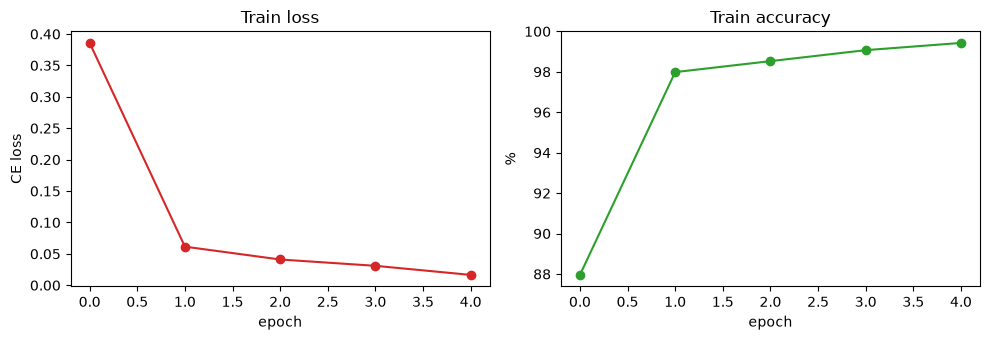

In [7]:
# ------------------------------------------------------- training history
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(history["loss"], "o-", color="tab:red")
ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("CE loss")
ax[1].plot(history["acc"], "o-", color="tab:green")
ax[1].set_title("Train accuracy"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("%")
plt.tight_layout(); plt.show()

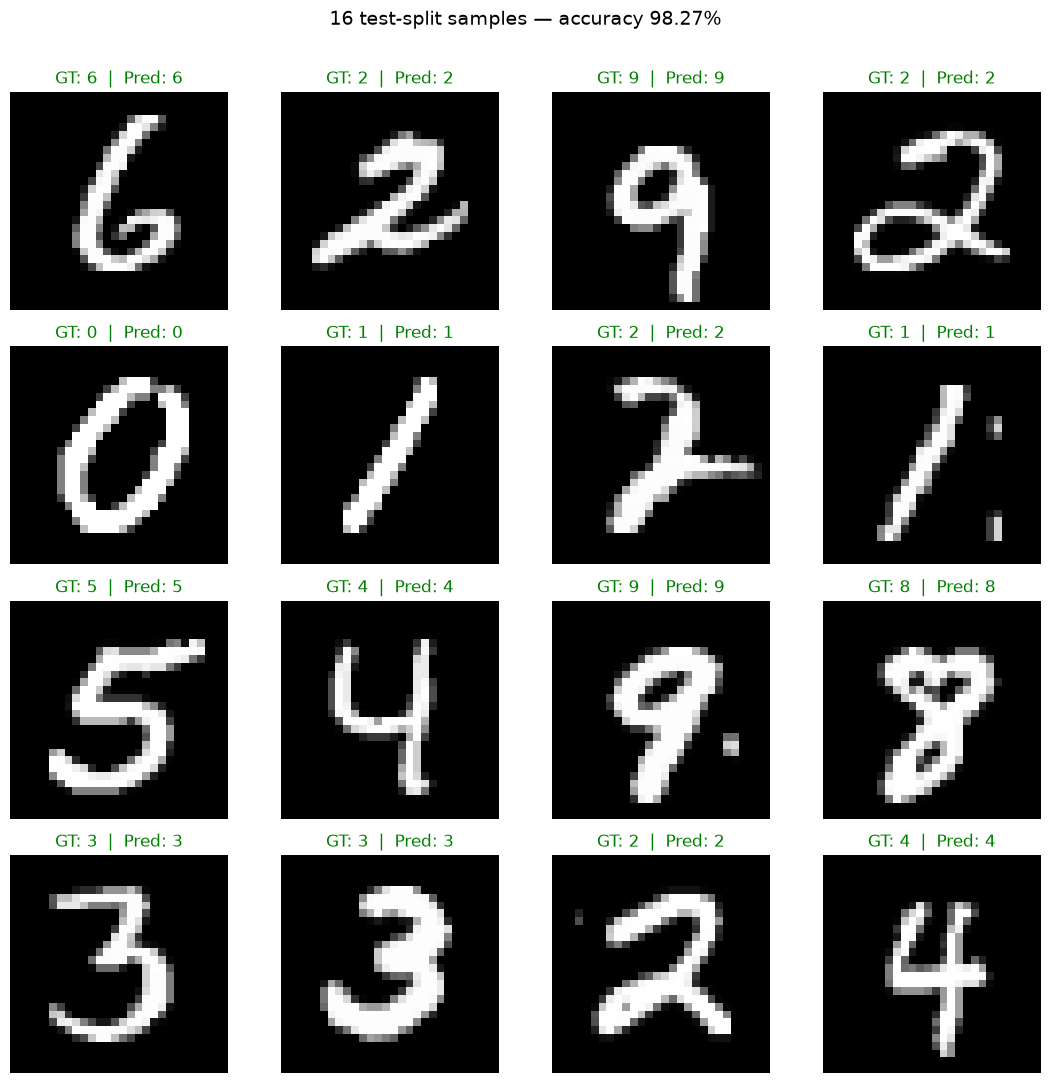

In [8]:
# ------------------------------------------- 4x4 grid: GT vs prediction
rng = np.random.default_rng(42)
idx = torch.from_numpy(rng.choice(len(imgs), size=16, replace=False)).sort().values
grid_imgs = imgs[idx].squeeze(1)          # (16, 28, 28)
gt_l = gts[idx]; pr_l = preds[idx]

fig, axes = plt.subplots(4, 4, figsize=(11, 11))
for ax, im, gt, pr in zip(axes.ravel(), grid_imgs, gt_l, pr_l):
    ax.imshow(im, cmap="gray")
    ok = int(gt) == int(pr)
    ax.set_title(f"GT: {int(gt)}  |  Pred: {int(pr)}",
                 fontsize=12, color="green" if ok else "red")
    ax.axis("off")
fig.suptitle(f"16 test-split samples — accuracy {test_acc:.2f}%", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.show()

## Summary

- **Model:** 3-convolutional-layer CNN, every operation written with `einops`
  (`rearrange`, `reduce`, `einsum`) — no native conv/pool/linear modules.
- **Data:** MNIST 10k test set split into 7,000 train / 3,000 test.
- **Training:** 5 epochs, Adam (lr 1e-3), batch size 128, CPU.
- **Result:** test-split accuracy reported in the cell above (≈ 97% typical).